In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from io import BytesIO
from PIL import Image
from load_traces import get_tuned_df

matplotlib.rcParams['svg.fonttype'] = 'none'

data_dir = '/Users/amonast/Desktop/miniscope/data'
CATEGORIES = ['Aggressive', 'Pro-Social', 'Social Avoidance']

color_map_categories = {
    'Aggressive':       '#fe0806',
    'Pro-Social':       '#55a0fb',
    'Social Avoidance': '#b856d7',
    'Asocial':          '#e7e6e6',
}

In [24]:
#nimals = sorted(pd.read_csv(f"{data_dir}/p_values_C1M1_R1.csv")['animal'].unique())  # or list them explicitly
animals =   ['C1F2','C1M1','C1M2', 'C2F1','C2M4', 'C3F3', 'C3F4', 
                'C3M2','C3M3', 'C3M4']
tuned, df = get_tuned_df(animals, data_dir)
zscores = df.xs('zscore', level='metric').reset_index()

tuned

,animal,session,behavior_type,tuned_cells
0,C1F2,R1,Aggressive,"[0, 13, 19, 33, 59]"
1,C1F2,R1,Baseline,"[19, 40]"
2,C1F2,R1,Pro-Social,"[3, 7, 9, 17, 19, 20, 22, 23, 26, 31, 37, 44, ..."
3,C1F2,R1,Social Avoidance,"[6, 17, 19, 33, 38, 58, 59]"
4,C1F2,R2,Aggressive,"[2, 7, 8, 10, 13, 18, 19, 21, 22, 30, 32, 36]"
...,...,...,...,...
66,C3M4,R1,Social Avoidance,"[16, 17]"
67,C3M4,R2,Aggressive,"[27, 42, 49, 51]"
68,C3M4,R2,Baseline,"[3, 4, 57, 58]"
69,C3M4,R2,Pro-Social,"[0, 5, 6, 7, 8, 11, 14, 15, 17, 18, 20, 26, 27..."


## Per-animal cluster maps

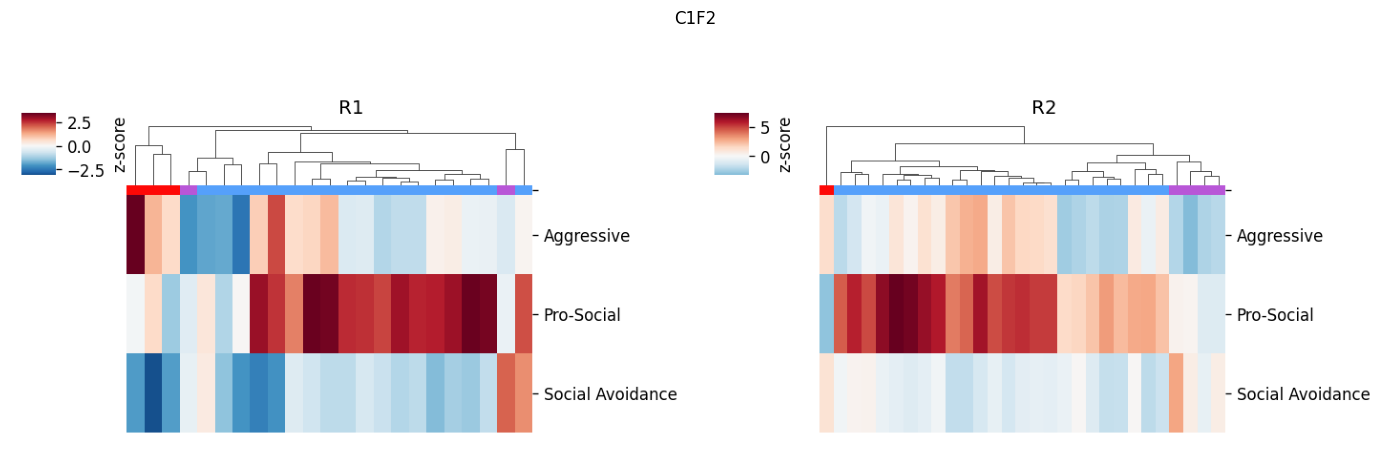

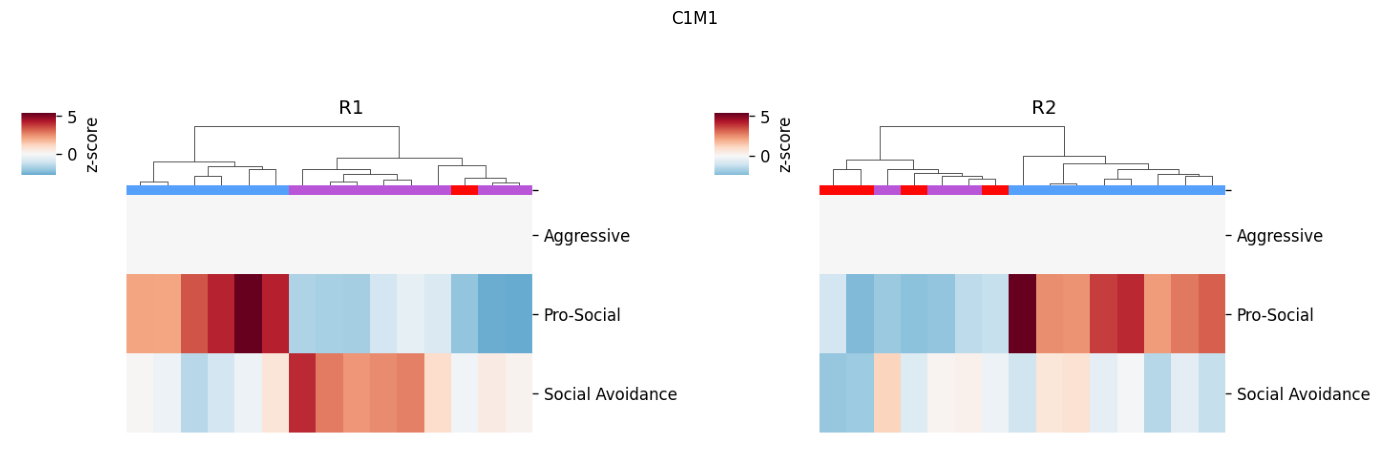

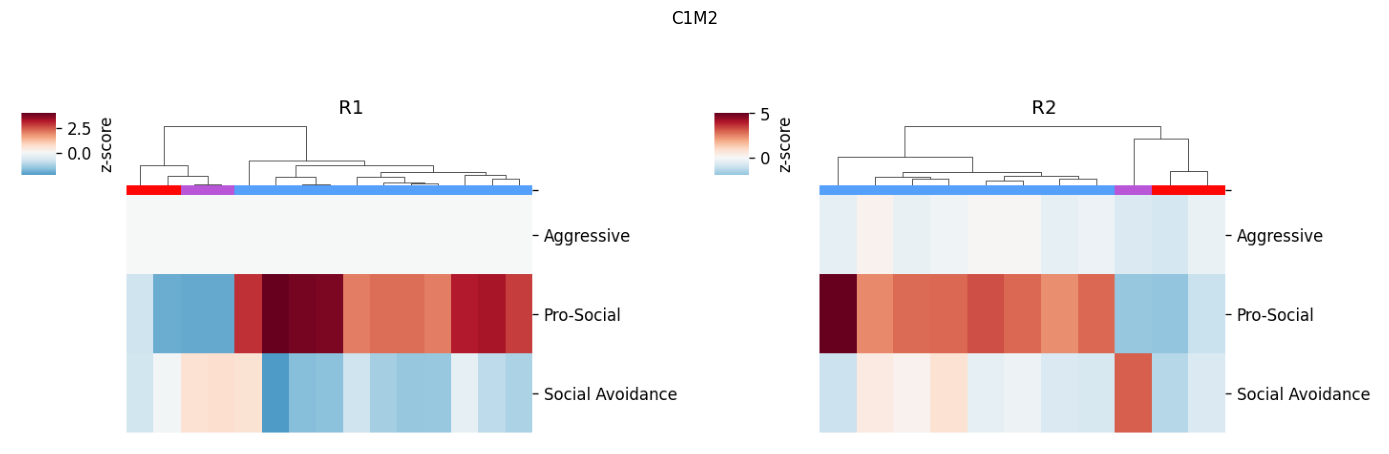

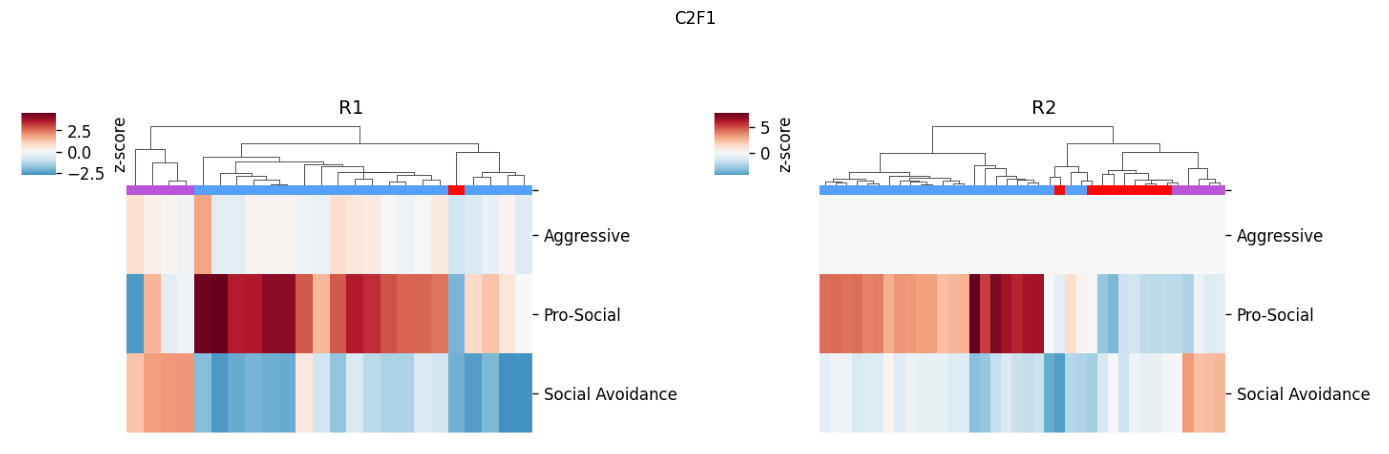

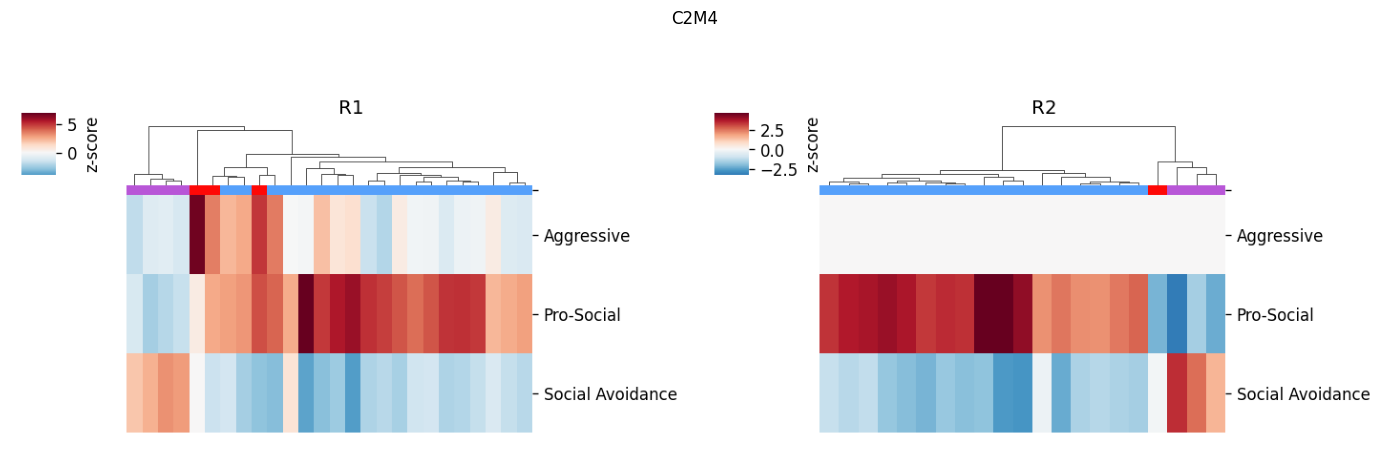

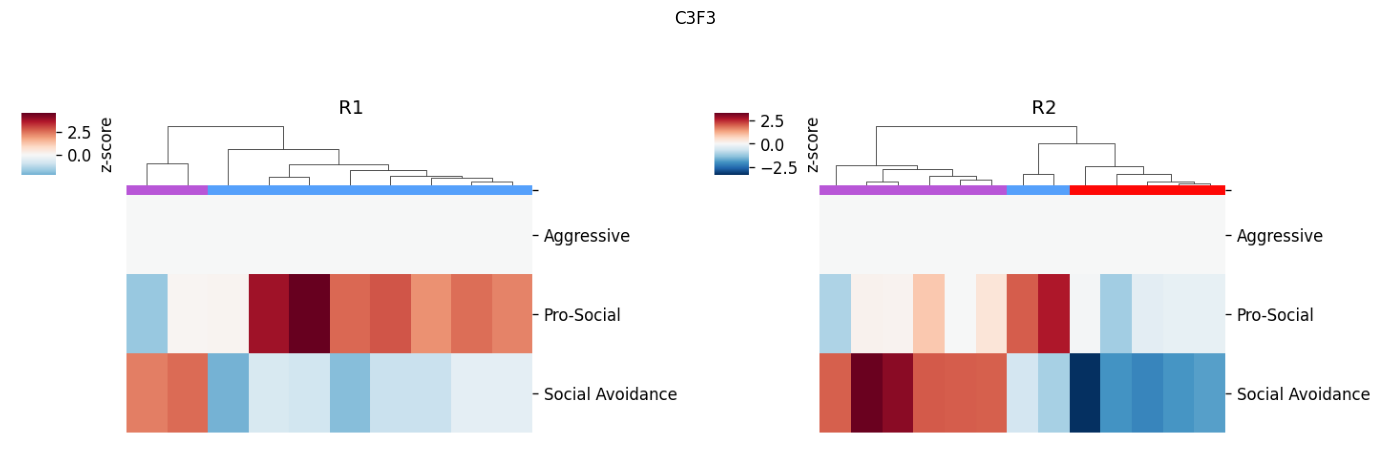

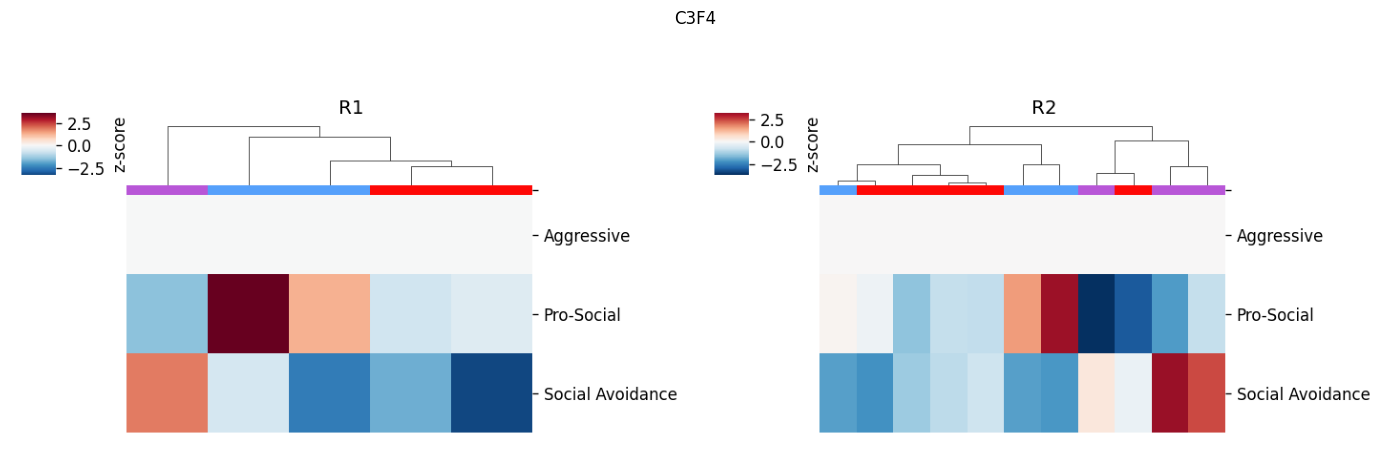

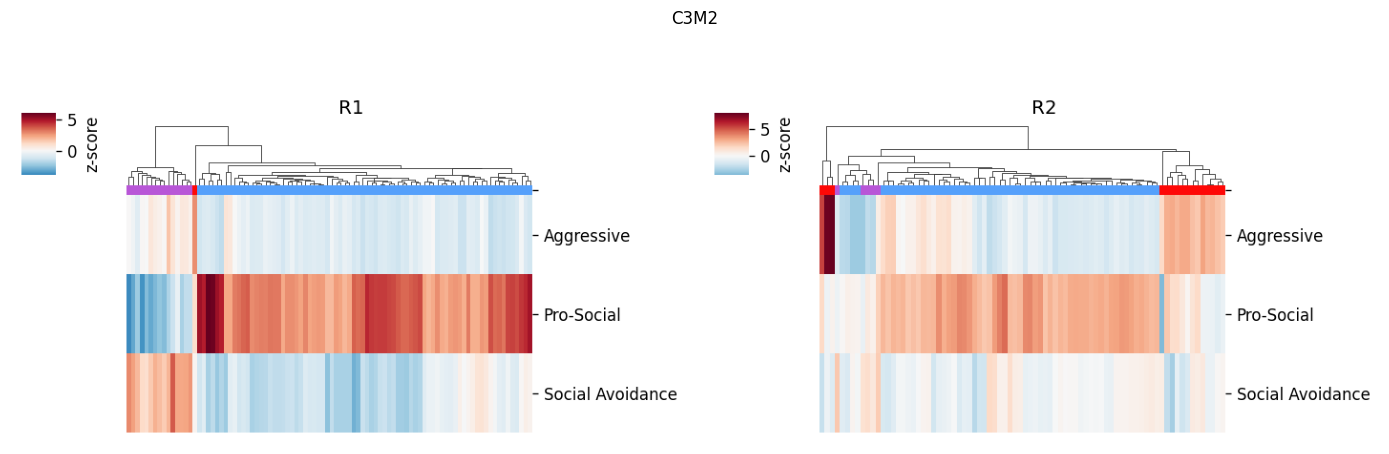

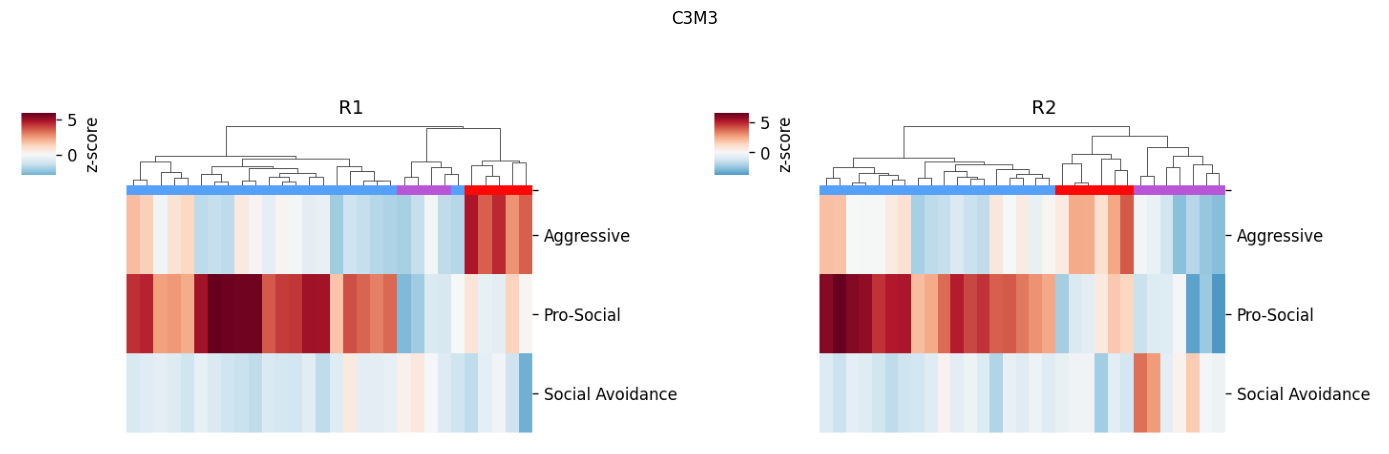

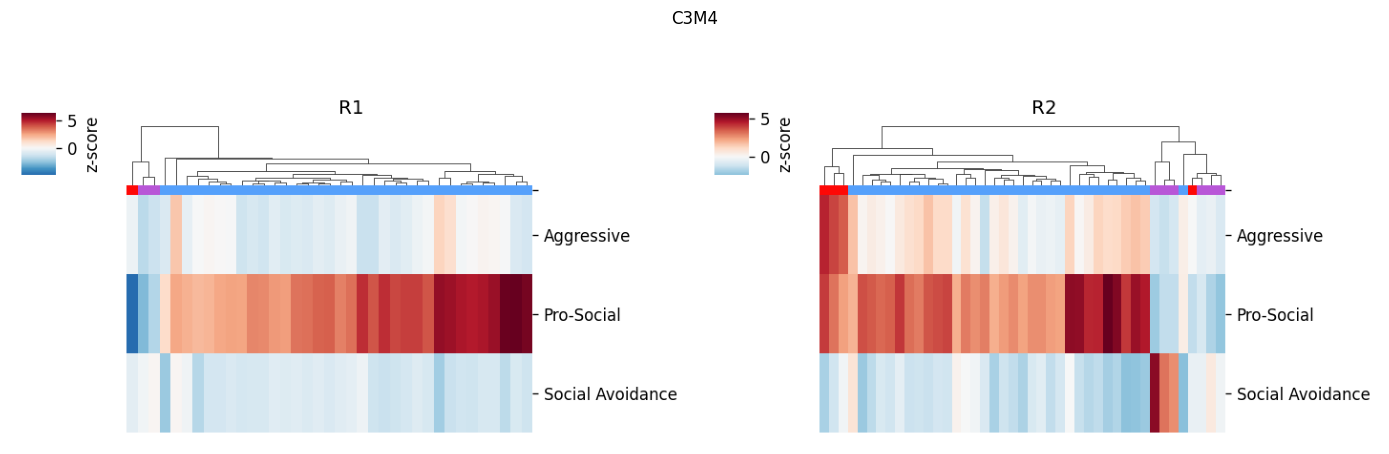

In [25]:
def make_clustermap_img(animal, session, color_map):
    grp = tuned[(tuned['animal'] == animal) & (tuned['session'] == session)]
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    if len(all_cells) < 2:
        return None

    rows = []
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)
        ]
        if z_row.empty:
            rows.append(pd.Series(0.0, index=all_cells, name=bt))
        else:
            rows.append(z_row[all_cells].iloc[0].rename(bt))

    clust_df = pd.DataFrame(rows).fillna(0)
    col_colors = clust_df.idxmax(axis=0).map(color_map)
    g = sns.clustermap(clust_df, row_cluster=False, col_colors=col_colors,
                       cmap='RdBu_r', center=0, xticklabels=False,
                       figsize=(6, 3), cbar_kws={'label': 'z-score'})
    g.fig.suptitle(session, y=1.02)
    buf = BytesIO()
    g.fig.savefig(buf, format='png', bbox_inches='tight', dpi=120)
    plt.close(g.fig)
    buf.seek(0)
    return Image.open(buf)


for animal in sorted(tuned['animal'].unique()):
    img_r1 = make_clustermap_img(animal, 'R1', color_map_categories)
    img_r2 = make_clustermap_img(animal, 'R2', color_map_categories)
    imgs = [(img, lbl) for img, lbl in [(img_r1, 'R1'), (img_r2, 'R2')] if img is not None]
    if not imgs:
        continue
    fig, axes = plt.subplots(1, len(imgs), figsize=(7 * len(imgs), 5))
    if len(imgs) == 1:
        axes = [axes]
    for ax, (img, lbl) in zip(axes, imgs):
        ax.imshow(img)
        ax.axis('off')
    fig.suptitle(animal, fontsize=12)
    plt.tight_layout()
    plt.show()

## All animals pooled

/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_69286/1611289141.py:64: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


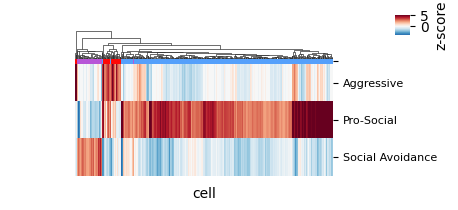

In [26]:
Z_THR = 1.0

pvalues = df.xs('pval', level='metric').reset_index()

# First pass: find which cells pass p<0.05 and z>Z_THR for at least one behavior
qualifying_cells = set()
for (animal, session), grp in tuned.groupby(['animal', 'session']):
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)]
        p_row = pvalues[
            (pvalues['animal'] == animal) &
            (pvalues['session'] == session) &
            (pvalues['behavior_type'] == bt)]
        for c in all_cells:
            z = float(z_row[c].iloc[0]) if not z_row.empty and c in z_row.columns else 0.0
            p = float(p_row[c].iloc[0]) if not p_row.empty and c in p_row.columns else 1.0
            if p < 0.05 and z > Z_THR:
                qualifying_cells.add(f"{animal}_{session}_{c}")

# Second pass: for qualifying cells, store raw z-scores for all behaviors
all_records = []
for (animal, session), grp in tuned.groupby(['animal', 'session']):
    all_cells = sorted(set(c for cells in grp['tuned_cells'] for c in cells))
    if not all_cells:
        continue
    for bt in CATEGORIES:
        z_row = zscores[
            (zscores['animal'] == animal) &
            (zscores['session'] == session) &
            (zscores['behavior_type'] == bt)]
        for c in all_cells:
            cell_id = f"{animal}_{session}_{c}"
            if cell_id not in qualifying_cells:
                continue
            val = float(z_row[c].iloc[0]) if not z_row.empty and c in z_row.columns else 0.0
            all_records.append({'cell': cell_id, 'behavior_type': bt, 'zscore': val})

clust_df = (pd.DataFrame(all_records)
              .pivot_table(index='cell', columns='behavior_type', values='zscore', fill_value=0)
              .reindex(columns=CATEGORIES, fill_value=0)
              .T)

col_colors = clust_df.idxmax(axis=0).map(color_map_categories)

g = sns.clustermap(
    clust_df,
    metric='euclidean',
    row_cluster=False,
    col_colors=col_colors,
    cmap='RdBu_r',
    center=0,
    vmax=5,
    figsize=(5,2),
    xticklabels=False,
    cbar_kws={'label': 'z-score'},
    cbar_pos=(.8,.9, .03, .1))
g.ax_heatmap.tick_params(labelsize=8)
g.ax_heatmap.set_ylabel('', fontsize=8)
#plt.suptitle(f'Z-scores of significantly tuned cells (p<0.05, z>{Z_THR}) — all animals')
plt.tight_layout()
plt.savefig('./figures/zscores_tunedcells_clustermap_zpos.svg', transparent=True)

In [27]:
clust_df

cell,C1F2_R1_17,C1F2_R1_19,C1F2_R1_20,C1F2_R1_22,C1F2_R1_23,C1F2_R1_26,C1F2_R1_3,C1F2_R1_31,C1F2_R1_33,C1F2_R1_37,...,C3M4_R2_56,C3M4_R2_59,C3M4_R2_6,C3M4_R2_60,C3M4_R2_62,C3M4_R2_63,C3M4_R2_64,C3M4_R2_65,C3M4_R2_7,C3M4_R2_8
behavior_type,,,,,,,,,,,,,,,,,,,,,
Aggressive,0.862499,2.323031,-0.505327,-0.899511,0.186234,0.740051,1.110108,-0.225093,3.503499,-1.033813,...,0.334853,1.457291,1.144851,0.085295,0.224721,0.030555,-0.654178,-0.320054,1.636176,-0.488403
Pro-Social,3.002224,2.526726,2.580936,2.954694,2.747158,3.442704,3.370877,3.451847,-0.095992,2.364639,...,2.063805,4.534631,2.936118,4.985137,2.676218,3.359328,2.312261,2.365090,3.563304,2.290438
Social Avoidance,-2.392870,-2.106098,-0.925946,-1.019311,-1.501158,-0.679567,-0.922470,-1.288942,-1.980831,-0.759614,...,-1.800419,-2.093457,-1.143309,-1.259856,-1.380819,-1.133324,-1.762138,-1.407326,-1.232881,-0.986495


## Pooled — animals with Aggressive behavior only

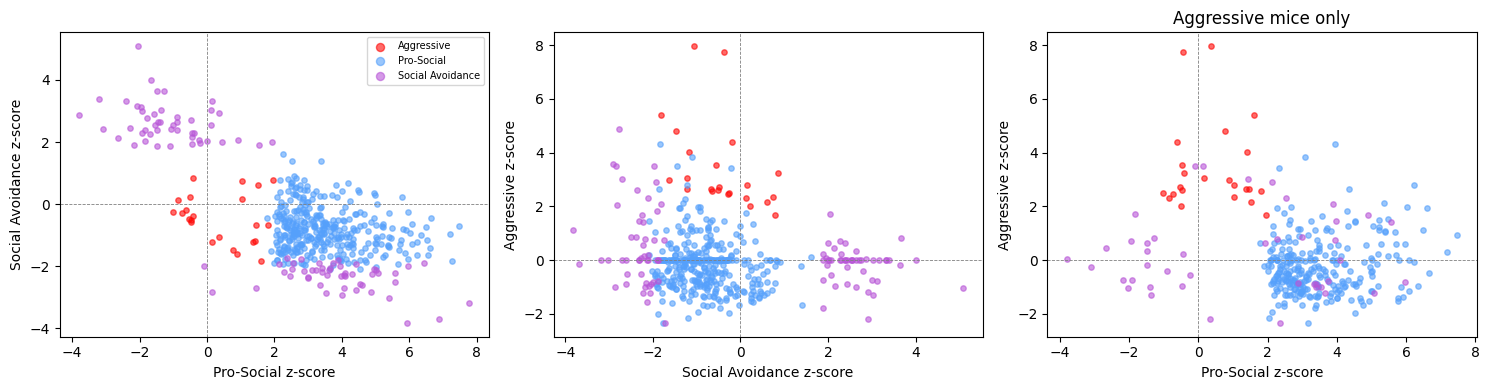

In [29]:
# clust_df is (behavior_type x cell) — transpose to get one row per cell
scatter_df = clust_df.T.copy()

# Color by the behavior each cell is actually tuned to (from tuned df)
cell_to_bt = {}
for _, row in tuned.iterrows():
    animal, session, bt = row['animal'], row['session'], row['behavior_type']
    for c in row['tuned_cells']:
        cell_id = f"{animal}_{session}_{c}"
        cell_to_bt[cell_id] = bt  # last write wins if a cell appears in multiple behaviors

scatter_df['tuned_to'] = scatter_df.index.map(cell_to_bt)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pairs = [('Pro-Social', 'Social Avoidance'), ('Social Avoidance', 'Aggressive')]
for ax, (x_bt, y_bt) in zip(axes, pairs):
    for bt in CATEGORIES:
        sub = scatter_df[scatter_df['tuned_to'] == bt]
        ax.scatter(sub[x_bt], sub[y_bt], color=color_map_categories[bt],
                   alpha=0.6, s=15, label=bt)
    ax.axhline(0, color='gray', linewidth=0.6, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.6, linestyle='--')
    ax.set_xlabel(x_bt + ' z-score')
    ax.set_ylabel(y_bt + ' z-score')

axes[0].legend(fontsize=7, markerscale=1.5)

# Third panel: Aggressive vs Pro-Social, aggressive mice only
scatter_df_agg = clust_df_agg.T.copy()
scatter_df_agg['tuned_to'] = scatter_df_agg.index.map(cell_to_bt)
ax = axes[2]
for bt in CATEGORIES:
    sub = scatter_df_agg[scatter_df_agg['tuned_to'] == bt]
    ax.scatter(sub['Pro-Social'], sub['Aggressive'], color=color_map_categories[bt],
               alpha=0.6, s=15, label=bt)
ax.axhline(0, color='gray', linewidth=0.6, linestyle='--')
ax.axvline(0, color='gray', linewidth=0.6, linestyle='--')
ax.set_xlabel('Pro-Social z-score')
ax.set_ylabel('Aggressive z-score')
ax.set_title('Aggressive mice only')

plt.tight_layout()
plt.show()


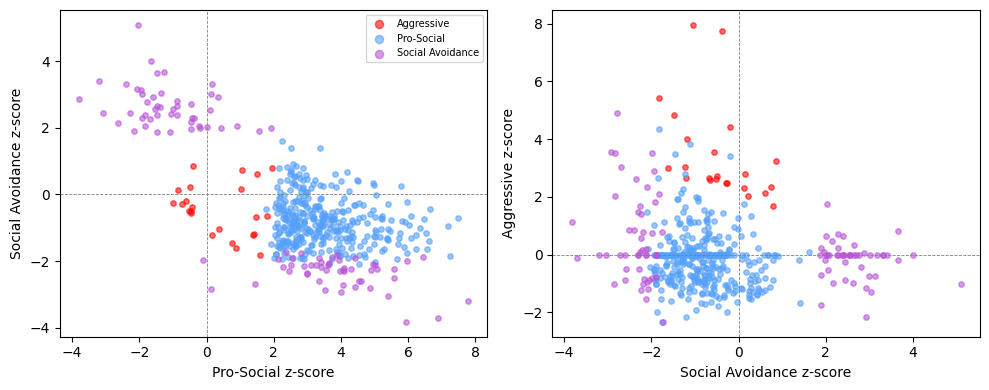

In [6]:
# clust_df is (behavior_type x cell) — transpose to get one row per cell
scatter_df = clust_df.T.copy()

# Color by the behavior each cell is actually tuned to (from tuned df)
cell_to_bt = {}
for _, row in tuned.iterrows():
    animal, session, bt = row['animal'], row['session'], row['behavior_type']
    for c in row['tuned_cells']:
        cell_id = f"{animal}_{session}_{c}"
        cell_to_bt[cell_id] = bt  # last write wins if a cell appears in multiple behaviors

scatter_df['tuned_to'] = scatter_df.index.map(cell_to_bt)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

pairs = [('Pro-Social', 'Social Avoidance'), ('Social Avoidance', 'Aggressive')]
for ax, (x_bt, y_bt) in zip(axes, pairs):
    for bt in CATEGORIES:
        sub = scatter_df[scatter_df['tuned_to'] == bt]
        ax.scatter(sub[x_bt], sub[y_bt], color=color_map_categories[bt],
                   alpha=0.6, s=15, label=bt)
    ax.axhline(0, color='gray', linewidth=0.6, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.6, linestyle='--')
    ax.set_xlabel(x_bt + ' z-score')
    ax.set_ylabel(y_bt + ' z-score')

axes[0].legend(fontsize=7, markerscale=1.5)
plt.tight_layout()
plt.show()